# MENA Web Presence Gap

**Question:** how many local businesses in seven MENA cities have no working website, where is the gap largest, and are these weaker businesses or good businesses that are simply offline?

**Data:** 10,802 Google Maps business listings collected for a website-building outreach project (Riyadh, Doha, Kuwait City, Cairo, Dubai, Amman, Istanbul). Each listing's website was checked and labelled `live`, `broken`, `social_only` or `none`. Only aggregated counts are published here, no names or contacts.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
ACCENT, MUTED, C2, C3 = '#D97757', '#C9C5BC', '#6A9BCC', '#B8A26A'

summary = pd.read_csv('data/summary.csv')
cities = pd.read_csv('data/cities.csv')
categories = pd.read_csv('data/categories.csv')
quality = pd.read_csv('data/quality.csv')
hot = pd.read_csv('data/hot.csv')
summary

,status,count
0,Live website,5278
1,No website,3851
2,Social media only,1207
3,Broken website,466


## 1. How big is the gap?
"Without a working website" = no website + social-media only + broken site.

In [2]:
total = summary['count'].sum()
without = summary.loc[summary.status != 'Live website', 'count'].sum()
print(f'Listings analysed: {total:,}')
print(f'Without a working website: {without:,} ({without/total:.1%})')
print(f'No website at all: {summary.set_index("status").loc["No website","count"]:,}')
print(f'Priority prospects (no site, 4.5+ stars, 100+ reviews, WhatsApp): {hot["count"].iloc[0]:,}')

Listings analysed: 10,802
Without a working website: 5,524 (51.1%)
No website at all: 3,851
Priority prospects (no site, 4.5+ stars, 100+ reviews, WhatsApp): 304


## 2. The gap by city
Collection was heavier in Riyadh (57% of rows), so cities are compared by **share**, not count.

**Istanbul is left out of this comparison.** Its 157 listings came from a lead search for businesses *without* a website, so 0 of 157 having a live site is how they were collected, not a finding about the city. They still count in the totals.

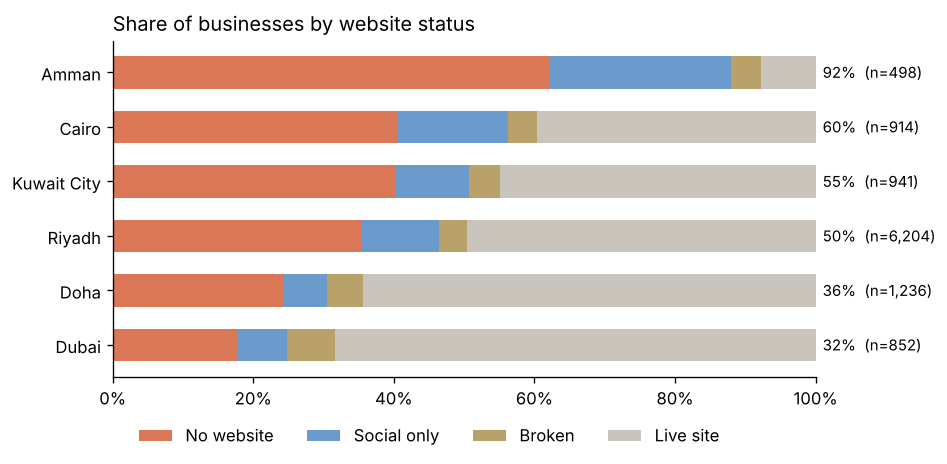

,city,total,without_share
5,Amman,498,0.921687
3,Cairo,914,0.603939
2,Kuwait City,941,0.550478
0,Riyadh,6204,0.504191
1,Doha,1236,0.355987
4,Dubai,852,0.316901


In [3]:
cities['without_share'] = (cities.no_website + cities.social_only + cities.broken) / cities.total
# Istanbul was collected from a no-website lead search, so its share is 100% by construction
comparable = cities[cities.city != 'Istanbul']
c = comparable.sort_values('without_share')
parts = [('no_website','No website',ACCENT),('social_only','Social only',C2),('broken','Broken',C3),('live','Live site',MUTED)]
fig, ax = plt.subplots(figsize=(8, 4))
left = pd.Series(0.0, index=c.index)
for col, label, color in parts:
    v = c[col] / c.total
    ax.barh(c.city, v, left=left, color=color, label=label, height=0.6)
    left += v
for i, (s, n) in enumerate(zip(c.without_share, c.total)):
    ax.text(1.01, i, f'{s:.0%}  (n={n:,})', va='center', fontsize=9)
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(lambda x, _: f'{x:.0%}')
ax.set_title('Share of businesses by website status', loc='left')
ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(0.45, -0.1), frameon=False)
plt.tight_layout(); plt.savefig('images/by_city.png', bbox_inches='tight'); plt.show()
comparable[['city','total','without_share']].sort_values('without_share', ascending=False)

## 3. Which sectors need websites most?
22 largest sectors (7,886 listings, 73% of the total).

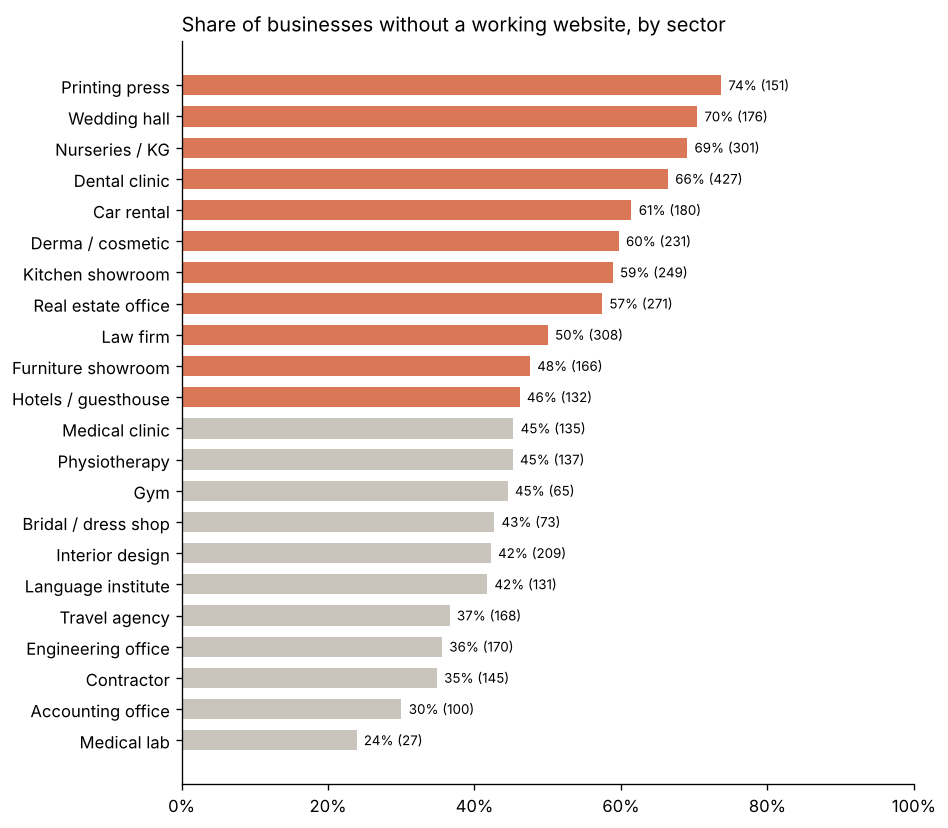

,category,total,no_working_site,share
18,Printing press,205,151,0.736585
17,Wedding hall,250,176,0.704000
6,Nurseries / KG,436,301,0.690367
0,Dental clinic,643,427,0.664075
15,Car rental,293,180,0.614334
9,Derma / cosmetic,387,231,0.596899
7,Kitchen showroom,423,249,0.588652
4,Real estate office,472,271,0.574153


In [4]:
categories['share'] = categories.no_working_site / categories.total
s = categories.sort_values('share')
med = s.share.median()
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(s.category, s.share, color=[ACCENT if v >= med else MUTED for v in s.share], height=0.65)
for i, (v, n) in enumerate(zip(s.share, s.no_working_site)):
    ax.text(v + 0.01, i, f'{v:.0%} ({n:,})', va='center', fontsize=8)
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(lambda x, _: f'{x:.0%}')
ax.set_title('Share of businesses without a working website, by sector', loc='left')
plt.tight_layout(); plt.savefig('images/by_sector.png', bbox_inches='tight'); plt.show()
categories.sort_values('share', ascending=False).head(8)

## 4. Are offline businesses weaker businesses?
Compare businesses **with** a live site against those **without** one on four signals.

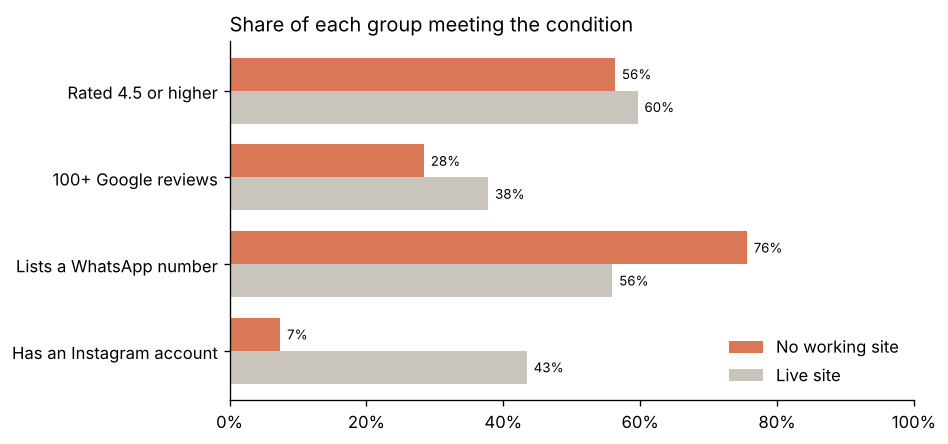

,metric,with_site_%,without_site_%
0,Rated 4.5 or higher,0.596,0.563
1,100+ Google reviews,0.378,0.284
2,Lists a WhatsApp number,0.559,0.756
3,Has an Instagram account,0.434,0.074


In [5]:
quality['with_site_%'] = quality.with_site / quality.with_site_n
quality['without_site_%'] = quality.without_site / quality.without_site_n
q = quality.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 3.8)); y = range(len(q)); h = 0.38
ax.barh([i + h/2 for i in y], q['without_site_%'], height=h, color=ACCENT, label='No working site')
ax.barh([i - h/2 for i in y], q['with_site_%'], height=h, color=MUTED, label='Live site')
for i in y:
    ax.text(q['without_site_%'][i] + 0.01, i + h/2, f"{q['without_site_%'][i]:.0%}", va='center', fontsize=8)
    ax.text(q['with_site_%'][i] + 0.01, i - h/2, f"{q['with_site_%'][i]:.0%}", va='center', fontsize=8)
ax.set_yticks(list(y)); ax.set_yticklabels(q.metric); ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(lambda x, _: f'{x:.0%}')
ax.set_title('Share of each group meeting the condition', loc='left'); ax.legend(frameon=False, loc='lower right')
plt.tight_layout(); plt.savefig('images/quality.png', bbox_inches='tight'); plt.show()
quality[['metric','with_site_%','without_site_%']].round(3)

### Is each gap real, or noise?
With about 5,000 businesses in each group, even small gaps can be real. A 95% confidence interval on each difference (two-proportion, normal approximation) shows which ones are, and how big.

In [6]:
import numpy as np
p1, p2 = quality['with_site_%'], quality['without_site_%']
se = np.sqrt(p1*(1-p1)/quality.with_site_n + p2*(1-p2)/quality.without_site_n)
quality['gap_pts'] = (p1 - p2) * 100
quality['ci_low'] = (p1 - p2 - 1.96*se) * 100
quality['ci_high'] = (p1 - p2 + 1.96*se) * 100
quality[['metric','gap_pts','ci_low','ci_high']].round(1)

,metric,gap_pts,ci_low,ci_high
0,Rated 4.5 or higher,3.3,1.4,5.1
1,100+ Google reviews,9.4,7.6,11.2
2,Lists a WhatsApp number,-19.7,-21.4,-17.9
3,Has an Instagram account,36.0,34.5,37.5


## Findings
1. **About half (51%) of listed businesses have no working website**, and 36% have no website at all.
2. **The gap is widest in Amman (92%)** and narrowest in Dubai (32%) and Doha (36%). Istanbul is excluded because its listings were collected from a no-website lead search.
3. **Offline does not mean low quality, but it does mean less visible.** Ratings are close: 56% vs 60% at 4.5+ stars, a real but small gap of 3.3 points (95% CI 1.4 to 5.1). Reviews differ more: 28% vs 38% have 100+ reviews. They lean on WhatsApp instead (76% vs 56%) and rarely have Instagram (7% vs 43%).
4. **Wedding halls, printing presses and nurseries** have the largest gap; medical labs and accounting offices the smallest.
5. **304 priority prospects** combine no website, strong ratings, 100+ reviews and a WhatsApp number to contact.

**Limitations:** listings come from targeted Google Maps searches, not a random sample of all businesses; website status was checked at collection time; city sample sizes differ a lot; Istanbul's listings came from a no-website lead search, so it is excluded from the city comparison; cities may differ in sector mix, which can drive part of the city gap.